# ALS implicit — retrain at threshold `rating >= 2` (validation-first)

This notebook is **self-contained**: every piece of matrix construction, model
training, and evaluation logic lives inline below (no `src/` split). The only shared
import is the raw ratings loader `movielens.data.load_ratings`.

Implicit-feedback ALS over the ratings matrix (positive = `rating >= 2`,
confidence = `1 + 40 * rating`, unobserved = `0`), trained on a chronological
80/10/10 split and evaluated with `NDCG@10` (primary), `precision@10`,
`recall@10`, and `hit-rate@10`. An **inline popularity baseline** (top-k movies
by training rating count) is compared at the same `>= 2` relevance; it is computed
inline and not registered to MLflow. The trained model is logged to
MLflow under the **`test`** alias with registry name `als-v1` and
`intent = als-v1-gte2`.


In [1]:
import os

os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")

import hashlib
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse


def repo_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "src" / "movielens").is_dir() and (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("repository root not found")


ROOT = repo_root()
sys.path.insert(0, str(ROOT / "src"))

import mlflow
from implicit.als import AlternatingLeastSquares

from movielens.data import RAW_DIR, load_ratings

SEED = 42
K = 10
FACTORS = 64
ALPHA = 40
REGULARIZATION = 0.1
ITERATIONS = 15
NUM_THREADS = 1
DTYPE = "float32"
THRESHOLD = 2
EXPERIMENT = "als"
REGISTRY_NAME = "als-v1"
MLFLOW_URI = (ROOT / "mlflow" / "mlruns").as_uri()

plt.rcParams["figure.figsize"] = (8, 3.5)


In [2]:
def data_version_hash():
    digest = hashlib.sha1((RAW_DIR / "ratings.dat").read_bytes()).hexdigest()
    return digest[:12]


def git_sha():
    out = subprocess.run(
        ["git", "rev-parse", "HEAD"], capture_output=True, text=True, check=True
    )
    return out.stdout.strip()


def precision_at_k(relevant, recommended, k=K):
    return float(np.mean([len(set(rec[:k]) & rel) / k for rel, rec in zip(relevant, recommended)]))


def recall_at_k(relevant, recommended, k=K):
    return float(
        np.mean([len(set(rec[:k]) & rel) / len(rel) if rel else 0.0 for rel, rec in zip(relevant, recommended)])
    )


def ndcg_at_k(relevant, recommended, k=K):
    vals = []
    for rel, rec in zip(relevant, recommended):
        dcg = sum(1.0 / np.log2(i + 2) for i, item in enumerate(rec[:k]) if item in rel)
        idcg = sum(1.0 / np.log2(i + 2) for i in range(min(k, len(rel))))
        vals.append(dcg / idcg if idcg > 0 else 0.0)
    return float(np.mean(vals))


def hit_rate_at_k(relevant, recommended, k=K):
    return float(np.mean([1.0 if (set(rec[:k]) & rel) else 0.0 for rel, rec in zip(relevant, recommended)]))


## 1. EDA

Dataset shape, sparsity, the positive-vs-unobserved imbalance, the raw rating
distribution, and the implicit signal (`rating >= 2` vs non-positive/unobserved).


n_users: 6040
n_movies: 3706
n_ratings: 1000209
sparsity (observed / users x movies): 0.0447
positive cells (rating >= 2): 944035
positive ratio: 0.9438
imbalance (positive / non-positive): 16.81
full-matrix cells: 22384240
unobserved cells: 21384031


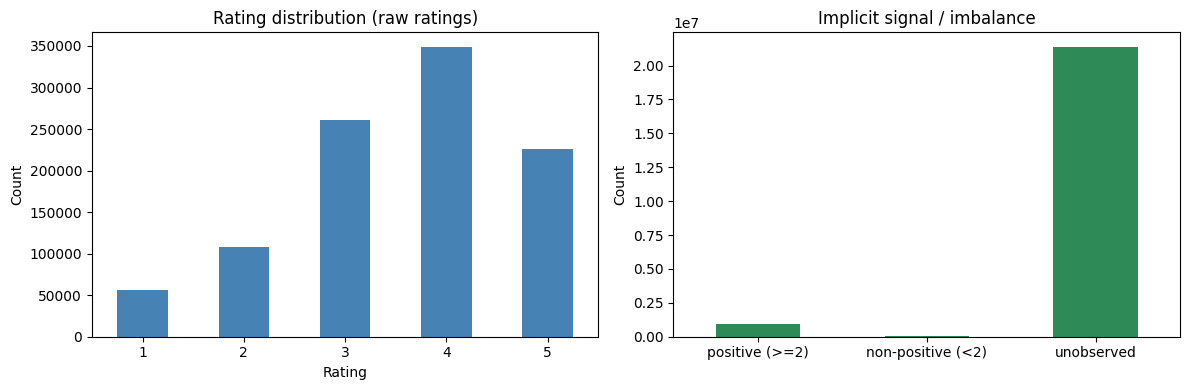

In [3]:
ratings = load_ratings()

n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
n_ratings = len(ratings)
sparsity = n_ratings / (n_users * n_movies)
n_positive = int((ratings["rating"] >= THRESHOLD).sum())

print("n_users:", n_users)
print("n_movies:", n_movies)
print("n_ratings:", n_ratings)
print("sparsity (observed / users x movies):", round(sparsity, 4))
print("positive cells (rating >= 2):", n_positive)
print("positive ratio:", round(n_positive / n_ratings, 4))
print("imbalance (positive / non-positive):", round(n_positive / (n_ratings - n_positive), 2))
print("full-matrix cells:", n_users * n_movies)
print("unobserved cells:", n_users * n_movies - n_ratings)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ratings["rating"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue", rot=0)
axes[0].set_title("Rating distribution (raw ratings)")
axes[0].set_xlabel("Rating")
axes[0].set_ylabel("Count")

signal = pd.Series(
    [n_positive, n_ratings - n_positive, n_users * n_movies - n_ratings],
    index=["positive (>=2)", "non-positive (<2)", "unobserved"],
)
signal.plot(kind="bar", ax=axes[1], color="seagreen", rot=0)
axes[1].set_title("Implicit signal / imbalance")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


## 2. Implicit confidence matrix + chronological split

Sort by `timestamp` (stable), split globally 80/10/10, and build the train-only
confidence matrix (observed `1 + 40 * rating`, unobserved `0`).


In [4]:
user_ids = np.sort(ratings["user_id"].unique())
movie_ids = np.sort(ratings["movie_id"].unique())
user_index = {int(u): i for i, u in enumerate(user_ids)}
movie_index = {int(m): i for i, m in enumerate(movie_ids)}

df = ratings.sort_values(["timestamp", "user_id", "movie_id"], kind="stable").reset_index(drop=True)
n = len(df)
train_end = int(0.8 * n)
val_end = int(0.9 * n)
train = df.iloc[:train_end]
val = df.iloc[train_end:val_end]
test = df.iloc[val_end:]

print("split sizes train/val/test:", len(train), len(val), len(test))
print("max train timestamp <= min val timestamp:",
      int(train["timestamp"].max()) <= int(val["timestamp"].min()))
print("max val timestamp <= min test timestamp:",
      int(val["timestamp"].max()) <= int(test["timestamp"].min()))

rows = train["user_id"].map(user_index).to_numpy(dtype=np.int32)
cols = train["movie_id"].map(movie_index).to_numpy(dtype=np.int32)
data = (1 + ALPHA * train["rating"]).to_numpy(dtype=np.float32)
confidence = sparse.csr_matrix((data, (rows, cols)), shape=(n_users, n_movies))

print("confidence matrix shape:", confidence.shape, "nnz:", confidence.nnz)
print("2-star confidence == 81:", bool((data == 81).any()))
print("4-star confidence == 161:", bool((data == 161).any()))
print("5-star confidence == 201:", bool((data == 201).any()))
print("unobserved cells are 0 (matrix has only train observations):", confidence.nnz == len(train))


split sizes train/val/test: 800167 100021 100021
max train timestamp <= min val timestamp: True
max val timestamp <= min test timestamp: True
confidence matrix shape: (6040, 3706) nnz: 800167
2-star confidence == 81: True
4-star confidence == 161: True
5-star confidence == 201: True
unobserved cells are 0 (matrix has only train observations): True


## 3. Train implicit ALS

`factors=64, alpha=40, regularization=0.1, iterations=15, random_state=42`, plus
`num_threads=1` and `dtype=float32` for reproducible single-threaded fitting
(recorded alongside the seed per the reproducibility caveat).


In [5]:
model = AlternatingLeastSquares(
    factors=FACTORS,
    alpha=ALPHA,
    regularization=REGULARIZATION,
    iterations=ITERATIONS,
    random_state=SEED,
    num_threads=NUM_THREADS,
    dtype=np.float32,
)
model.fit(confidence, show_progress=False)

print("model config:", {
    "factors": model.factors,
    "alpha": model.alpha,
    "regularization": model.regularization,
    "iterations": model.iterations,
    "random_state": model.random_state,
    "num_threads": model.num_threads,
    "dtype": str(model.dtype),
})
print("user_factors:", model.user_factors.shape, "item_factors:", model.item_factors.shape)


model config: {'factors': 64, 'alpha': 40, 'regularization': 0.1, 'iterations': 15, 'random_state': 42, 'num_threads': 1, 'dtype': 'float32'}
user_factors: (6040, 64) item_factors: (3706, 64)


## 4. Evaluation — ranking vs popularity baseline

Per test user: `relevant` = held-out test items with `rating >= 2`; candidates = all
items not rated in train; score with ALS, rank descending, take top-10. Users with an
empty relevant set are excluded. Mean `NDCG@10` (primary), `precision@10`,
`recall@10`, `hit-rate@10`.


In [6]:
test_users = sorted(test["user_id"].unique().tolist())
relevant = {
    u: set(test.loc[(test["user_id"] == u) & (test["rating"] >= THRESHOLD), "movie_id"])
    for u in test_users
}
train_rated = train.groupby("user_id")["movie_id"].apply(set).to_dict()

eval_users = [u for u in test_users if relevant[u]]
n_excluded = len(test_users) - len(eval_users)

uidx = np.array([user_index[u] for u in eval_users])
scores = model.user_factors[uidx] @ model.item_factors.T

movie_arr = np.array(movie_ids)

model_recs = {}
for i, u in enumerate(eval_users):
    s = scores[i].copy()
    mask = np.array([int(m) in train_rated.get(u, set()) for m in movie_arr])
    s[mask] = -np.inf
    order = np.argsort(-s, kind="stable")
    model_recs[u] = movie_arr[order][:K].tolist()

rel_list = [relevant[u] for u in eval_users]
model_rec_list = [model_recs[u] for u in eval_users]

metrics = {
    "ndcg@10": ndcg_at_k(rel_list, model_rec_list),
    "precision@10": precision_at_k(rel_list, model_rec_list),
    "recall@10": recall_at_k(rel_list, model_rec_list),
    "hit-rate@10": hit_rate_at_k(rel_list, model_rec_list),
}

summary = pd.DataFrame(
    {
        "ndcg@10": [metrics["ndcg@10"]],
        "precision@10": [metrics["precision@10"]],
        "recall@10": [metrics["recall@10"]],
        "hit-rate@10": [metrics["hit-rate@10"]],
    },
    index=["als model"],
)

print("test users (total):", len(test_users))
print("test users excluded (empty relevant set):", n_excluded)
print("test users evaluated:", len(eval_users))
print()
print(summary.round(6).to_string())


test users (total): 1209
test users excluded (empty relevant set): 1
test users evaluated: 1208

            ndcg@10  precision@10  recall@10  hit-rate@10
als model  0.062205      0.061093   0.009941     0.345199


## 4b. Popularity baseline (inline) — comparison

Re-added per directive: an **inline** popularity baseline (top-k movies by training
rating count, excluding each user's train-rated items) at the same `rating >= 2`
relevance and on the same 1208 test users. It is model-independent (one set of numbers
shared across all retrained models) and is **not** registered to MLflow.


In [ ]:
def popularity_recommendations(eval_users, train_rated, train, k=K):
    pop_rank = train.groupby("movie_id").size().sort_values(ascending=False).index.to_numpy()
    recs = {}
    for u in eval_users:
        rated = train_rated.get(u, set())
        top = [int(m) for m in pop_rank if m not in rated][:k]
        recs[u] = top
    return recs


pop_recs = popularity_recommendations(eval_users, train_rated, train)
pop_rec_list = [pop_recs[u] for u in eval_users]

pop_metrics = {
    "ndcg@10": ndcg_at_k(rel_list, pop_rec_list),
    "precision@10": precision_at_k(rel_list, pop_rec_list),
    "recall@10": recall_at_k(rel_list, pop_rec_list),
    "hit-rate@10": hit_rate_at_k(rel_list, pop_rec_list),
}

comparison = pd.DataFrame(
    {
        "ndcg@10": [metrics["ndcg@10"], pop_metrics["ndcg@10"], metrics["ndcg@10"] - pop_metrics["ndcg@10"]],
        "precision@10": [metrics["precision@10"], pop_metrics["precision@10"], metrics["precision@10"] - pop_metrics["precision@10"]],
        "recall@10": [metrics["recall@10"], pop_metrics["recall@10"], metrics["recall@10"] - pop_metrics["recall@10"]],
        "hit-rate@10": [metrics["hit-rate@10"], pop_metrics["hit-rate@10"], metrics["hit-rate@10"] - pop_metrics["hit-rate@10"]],
    },
    index=["als model", "popularity baseline", "delta (model - popularity)"],
)
print(comparison.round(6).to_string())


## 5. Log to MLflow (under the `test` alias)

Metrics, params, and the model artifact are logged; tags `code_version`,
`data_version`, and `intent` are set. The newly registered version is given the
**`test`** alias (never `Staging`/`Production`).


In [7]:
class ALSRecommender(mlflow.pyfunc.PythonModel):
    def __init__(self, user_factors, item_factors, user_ids, movie_ids):
        self.user_factors = user_factors
        self.item_factors = item_factors
        self.user_ids = user_ids
        self.movie_ids = movie_ids
        self.user_index = {int(u): i for i, u in enumerate(user_ids)}
        self.movie_index = {int(m): i for i, m in enumerate(movie_ids)}

    def predict(self, context, model_input):
        df = model_input
        ui = df["user_id"].map(self.user_index).to_numpy()
        mi = df["movie_id"].map(self.movie_index).to_numpy()
        return (self.user_factors[ui] * self.item_factors[mi]).sum(axis=1)


mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)
client = mlflow.tracking.MlflowClient()

params = dict(
    factors=FACTORS,
    alpha=ALPHA,
    regularization=REGULARIZATION,
    iterations=ITERATIONS,
    random_state=SEED,
    num_threads=NUM_THREADS,
    dtype=DTYPE,
)

metric_log = {k.replace("@", "_at_"): v for k, v in metrics.items()}

with mlflow.start_run() as active_run:
    run_id = active_run.info.run_id
    mlflow.log_params(params)
    mlflow.log_metrics(metric_log)
    mlflow.set_tags(
        {
            "code_version": git_sha(),
            "data_version": data_version_hash(),
            "intent": "als-v1-gte2",
        }
    )
    info = mlflow.pyfunc.log_model(
        artifact_path="model",
        python_model=ALSRecommender(
            model.user_factors, model.item_factors, user_ids, movie_ids
        ),
        registered_model_name=REGISTRY_NAME,
    )
    version = info.registered_model_version
    client.set_registered_model_alias(REGISTRY_NAME, "test", version)

print("run_id:", run_id)
print("registered version:", version)
print("test alias ->", client.get_model_version_by_alias(REGISTRY_NAME, "test").version)
print("code_version:", git_sha())
print("data_version:", data_version_hash())


C:\Users\Franco\.pyenv\pyenv-win\versions\3.12.10\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


2026/10/18 23:39:50 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


2026/10/18 23:39:50 WARNING mlflow.pyfunc: Passing a Python object as `python_model` causes it to be serialized using CloudPickle, it requires exercising caution as Python object serialization mechanisms may execute arbitrary code during deserialization.Consider using a file path (str or Path) instead. See https://mlflow.org/docs/latest/ml/model/models-from-code/ for details.


Successfully registered model 'als-v1'.
Created version '1' of model 'als-v1'.


run_id: cb2fc4575d844cd69de7584a2bf46715
registered version: 1
test alias -> 1
code_version: 172af8dd3b087c250ce2c8aaaa38104e548b3a39


data_version: 28770e0e10e2
